## HAR

In [2]:
import pandas as pd
from sklearn.datasets import fetch_openml

X, y = fetch_openml('har', version=1, return_X_y=True, as_frame=True)

In [3]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10299 entries, 0 to 10298
Columns: 561 entries, V1 to V561
dtypes: float64(561)
memory usage: 44.1 MB


In [4]:
y.head()

0    5
1    5
2    5
3    5
4    5
Name: Class, dtype: category
Categories (6, object): ['1', '2', '3', '4', '5', '6']

In [5]:
max(X.isna().sum())

0

In [6]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [7]:
from sklearn.decomposition import PCA
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

n_comps = X_pca.shape
n_comps

(10299, 104)

In [8]:
import matplotlib.pyplot as plt
import numpy as np

(10299, 2)
[5 5 5 5 5 5 5 5 5 5]


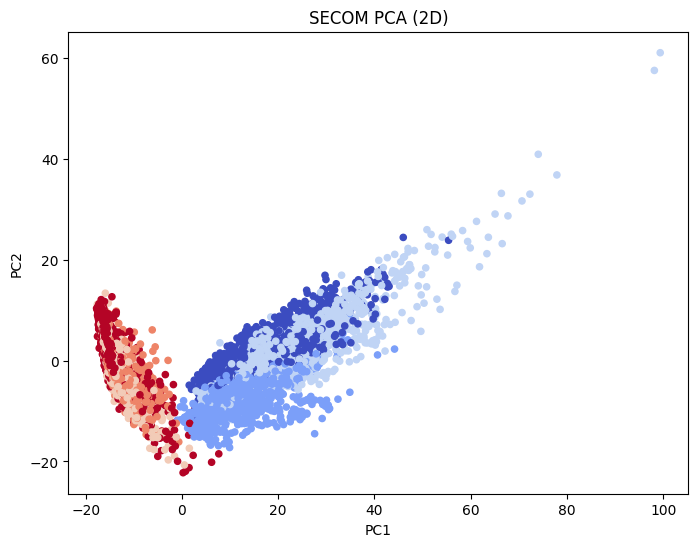

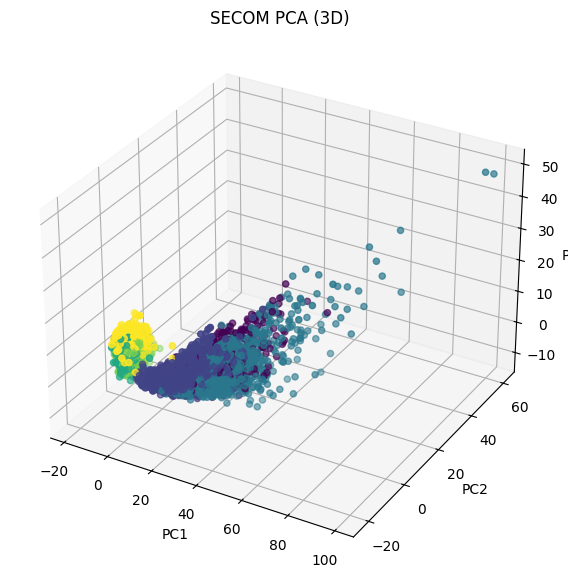

In [9]:
pca_2d = PCA(n_components=2)
x_2 = pca_2d.fit_transform(X_scaled)

print(x_2.shape)

y = y.astype(int)
colors = np.array(y)
print(colors[:10])

plt.figure(figsize=(8, 6))
plt.scatter(x_2[:, 0], x_2[:, 1], c=colors, cmap="coolwarm", s=20)
plt.title("SECOM PCA (2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

pca_3 = PCA(n_components=3)
X_3 = pca_3.fit_transform(X_scaled)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_3[:, 0], X_3[:, 1], X_3[:, 2], c=colors, s=20)
ax.set_title("SECOM PCA (3D)")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
plt.show()

(10299, 2)


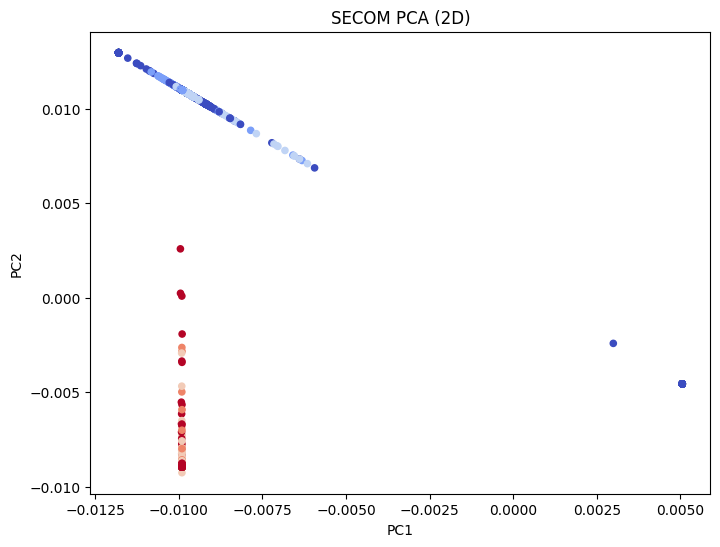

In [10]:
from sklearn.manifold import LocallyLinearEmbedding
lle = LocallyLinearEmbedding(n_components=2, n_neighbors=10, random_state=42)
X_unrolled = lle.fit_transform(X_scaled)
print(X_unrolled.shape)

plt.figure(figsize=(8, 6))
plt.scatter(X_unrolled[:, 0], X_unrolled[:, 1], c=colors, cmap="coolwarm", s=20)
plt.title("SECOM PCA (2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [12]:
k_range = list(range(2, 10))
sil_scores = []

best_sil = -1
best_k = 2

for k in k_range:
    kmean = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)

    sil_score = silhouette_score(X_pca, kmean.labels_)
    sil_scores.append(sil_score)
    if sil_score > best_sil:
        best_sil = sil_score
        best_k = k


print(best_k)
print(sil_scores)

2
[0.4125161148309213, 0.33128156215694093, 0.16245934397034711, 0.139998215051644, 0.12227668350205688, 0.08864764589519926, 0.08298919056797113, 0.08773738007603417]


In [30]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=15, min_samples=15)
dbscan.fit(X_pca)
print(max(dbscan.labels_) + 1)

4


In [ ]:
import hdbscan

hdb = hdbscan.HDBSCAN()
hdb.fit(X)
print(max(hdb.labels_) + 1)


4


In [33]:
hdb = hdbscan.HDBSCAN()
hdb.fit(x_2)
print(max(hdb.labels_) + 1)

2


In [44]:
print(x_2.shape)

(10299, 2)


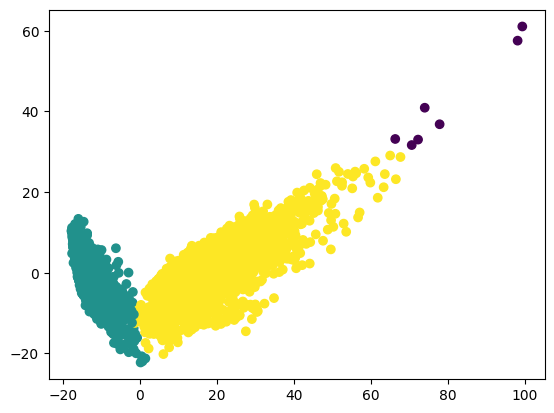

In [46]:
plt.scatter(
    x_2[:, 0], x_2[:, 1], c=hdb.labels_
)
plt.show()

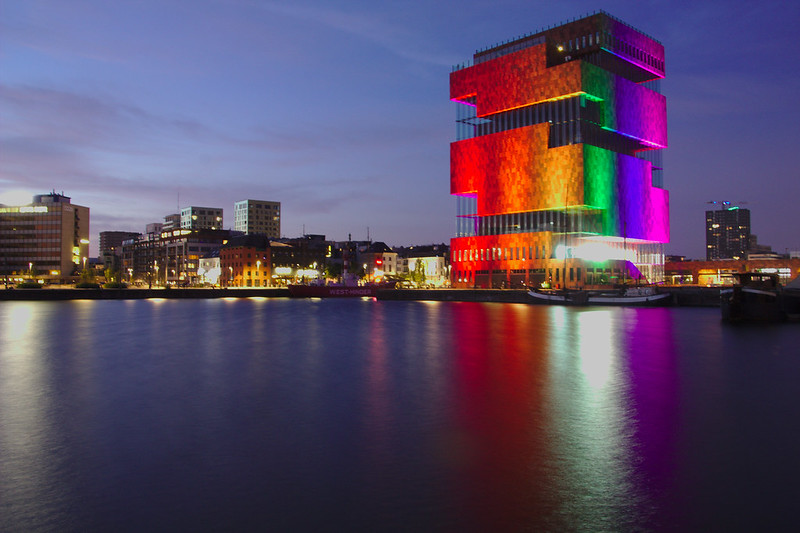

In [41]:
from PIL import Image

img = Image.open('./data/rainbow.jpg')
img

In [56]:
img = np.array(img)
img.shape

X = img.reshape(-1, 3)
nado = img.shape

In [71]:
kmeanns = KMeans(n_clusters=10, random_state=42, n_init=10).fit(X)
seg_img = kmeanns.cluster_centers_[kmeanns.labels_]
seg_img = seg_img.reshape(nado)

seg_img.shape

(533, 800, 3)

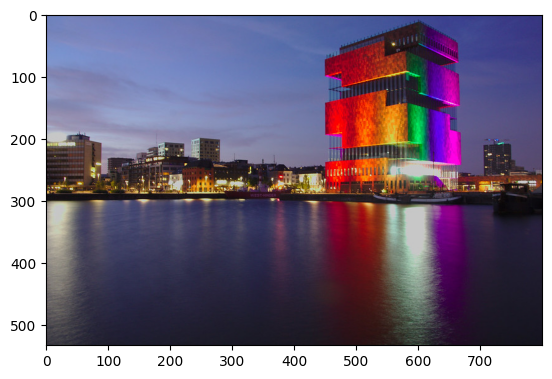

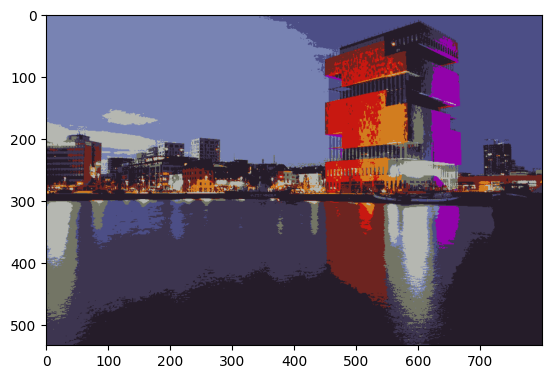

In [72]:
plt.imshow(img)
plt.show()

# print(max(seg_img[:, 0, 0]))
plt.imshow(seg_img.astype(int))
plt.show()